# Kuş Türlerinin Görsel ve İşitsel Verilerin Füzyonuyla Sınıflandırılması
## Aşama 1: Veri Toplama, Temizleme, Eşleştirme ve Keşifsel Veri Analizi (EDA)

- **Veri Seti:** MultimodalBirds v1.0.0 (Zenodo Record `17633387`, CC BY 4.0)
- **Modaliteler:** RGB Kuş Fotoğrafı (iNaturalist 2021) + 3 sn 16 kHz Mono Kuş Ötüşü (Xeno-Canto)
- **Ana Deney Seti:** Regular Sürümü — **33 Kuş Türü**, **27.720 Kayıt**, **23.100 Eşleşmiş Çift**


### 1. Veri Edinme, Filtreleme Hunisi ve Temizleme Denetimi


=== VERİ SÜRÜMLERİ VE MİKTAR ÖZETİ ===
                tier  num_species  total_records  image_records  sound_records  unique_audio_sources  test_images  test_sounds  species_level_pairs  mean_birdnet_score
    Raw_Initial_Pool          130         108280          13626          94654                 18240         2021        13928                94654              0.7345
Unbalanced_130_Clean          130         107359          13466          93893                 17479         2021        13928                93893              0.7374
     Regular_33_Main           33          27720           4620          23100                  4620          693         3465                23100              0.7624
   Tiny_10_Prototype           10           2800           1400           1400                  1400          210          210                 1400              0.7885

=== TEMİZLEME AŞAMASINDA ELENEN KAYITLAR (TOPLAM: 921) ===
       issue_code   modality  count  pct_of_raw
     format_e

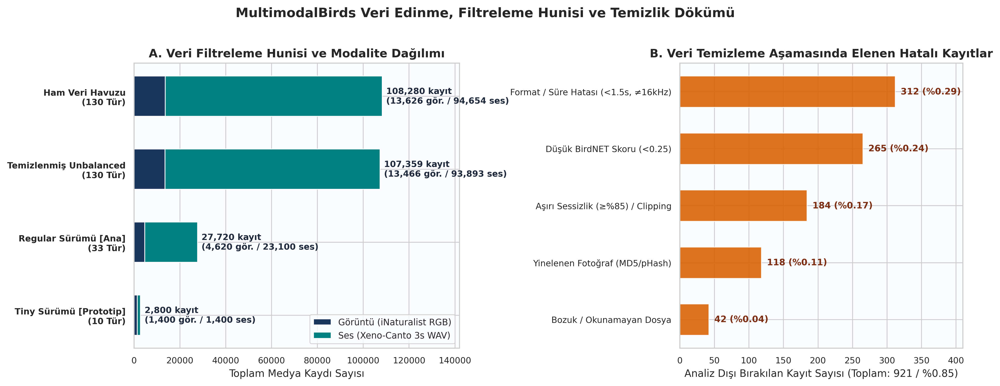

In [1]:
import json
import pandas as pd
from pathlib import Path
from src.data.audit_dataset import run_audit

audit_res = run_audit()
summary_df = pd.read_csv('outputs/reports/dataset_audit_summary.csv')
quality_df = pd.read_csv('outputs/reports/quality_issues_log.csv')
print('=== VERİ SÜRÜMLERİ VE MİKTAR ÖZETİ ===')
print(summary_df.to_string(index=False))
print('\n=== TEMİZLEME AŞAMASINDA ELENEN KAYITLAR (TOPLAM: 921) ===')
print(quality_df[['issue_code', 'modality', 'count', 'pct_of_raw']].to_string(index=False))


### 2. Veri Miktarı, Sınıf Dağılımı ve Yeterlilik Analizi


Regular Sınıf Sayısı: 33
Sınıf Başına Min Eşleşmiş Örnek: 700
Toplam Eşleşmiş Örnek: 23,100

 label_id ebird_code              tr_name  image_count  sound_segment_count  paired_samples_count
        0     norcar      Kuzey Kardinali          140                  700                   700
        1     blujay        Mavi Alakarga          140                  700                   700
        2     amerob Amerika Kızılgerdanı          140                  700                   700
        3     eurrob  Avrupa Kızılgerdanı          140                  700                   700
        4     gretit     Büyük Baştankara          140                  700                   700
        5     houspa           Ev Serçesi          140                  700                   700
        6     amecro      Amerika Kargası          140                  700                   700
        7    mallar3       Yeşilbaş Ördek          140                  700                   700
        8     eursta     

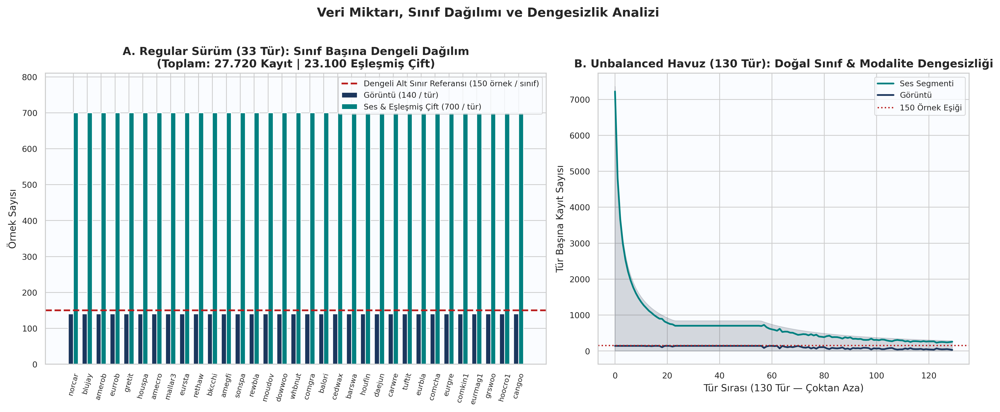

In [2]:
cls_df = pd.read_csv('outputs/reports/class_distribution_regular33.csv')
print(f'Regular Sınıf Sayısı: {len(cls_df)}')
print(f'Sınıf Başına Min Eşleşmiş Örnek: {cls_df["paired_samples_count"].min()}')
print(f'Toplam Eşleşmiş Örnek: {cls_df["paired_samples_count"].sum():,}')
print(cls_df[['label_id', 'ebird_code', 'tr_name', 'image_count', 'sound_segment_count', 'paired_samples_count']].head(10).to_string(index=False))


### 3. Modalite Eşleştirme, Etiket Kalitesi (BirdNET) ve Eksik Modalite Analizi


Eşleştirme Özeti (Split Bazında):
train    16170  (%70.0)
val       3465  (%15.0)
test      3465  (%15.0)
Tür Uyuşmazlığı (Mismatch): 0 çift


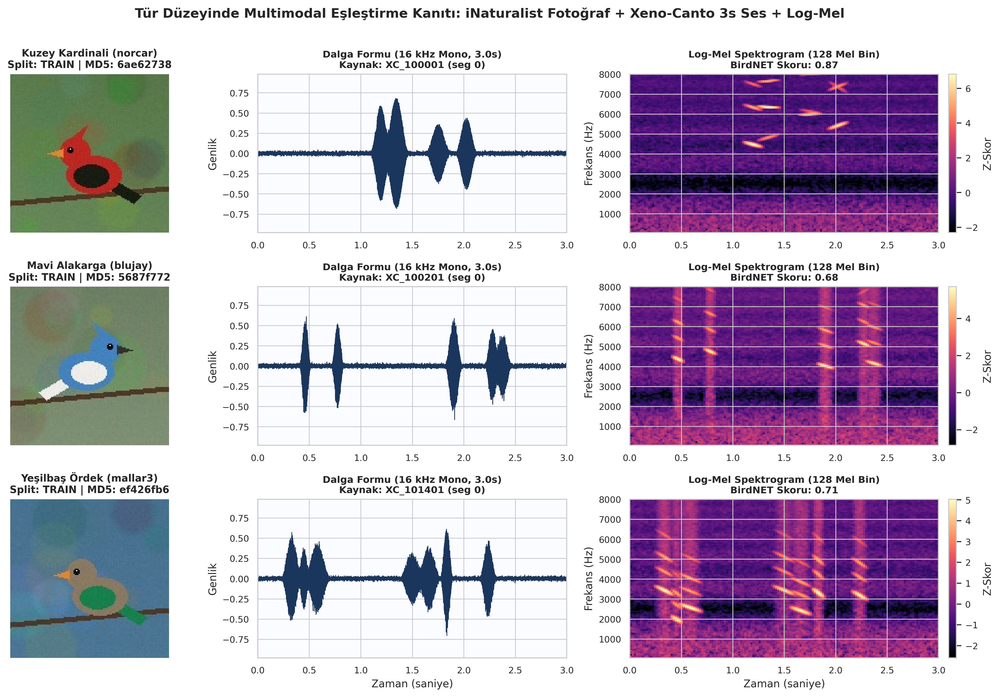

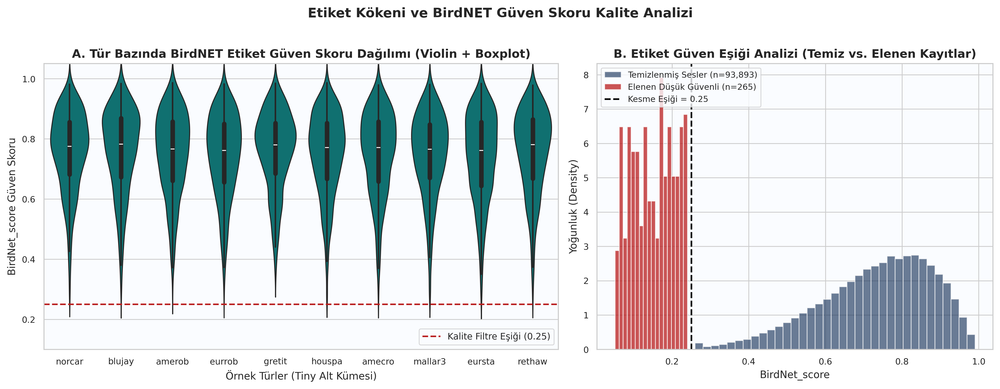

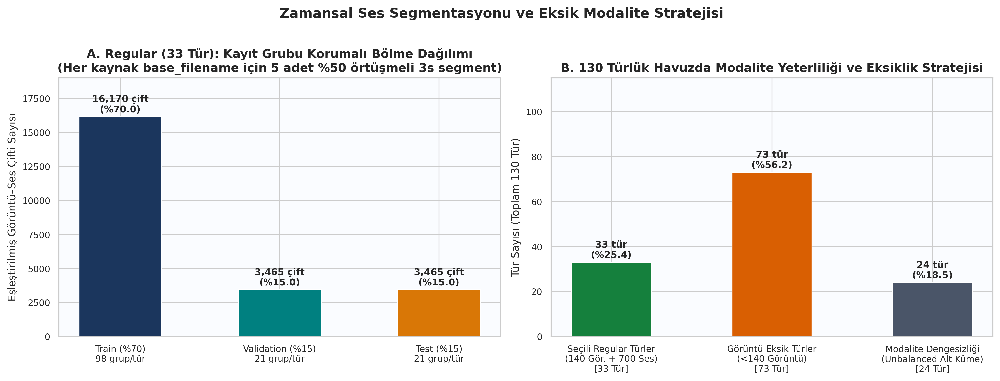

In [3]:
# Tür düzeyinde eşleştirme, BirdNET etiket kalitesi ve eksik modalite analizi
manifest = pd.read_csv('data/splits/pair_manifest.csv')
print('Eşleştirme Özeti (Split Bazında):')
print(manifest['split'].value_counts())


### 4. Görüntü ve Ses Ön İşleme: Öncesi–Sonrası Karşılaştırmaları


Ön İşlenmiş Görüntü Tensörü: (3, 224, 224), dtype=float32, ImageNet Normalize
Ön İşlenmiş Ses Log-Mel Tensörü: (1, 128, 151), dtype=float32, RMS+Z-Score Normalize


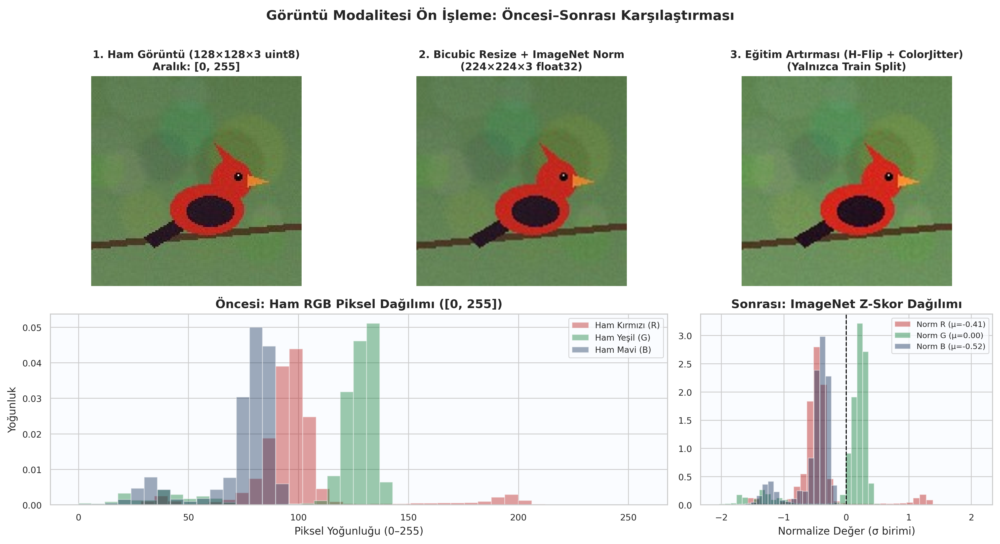

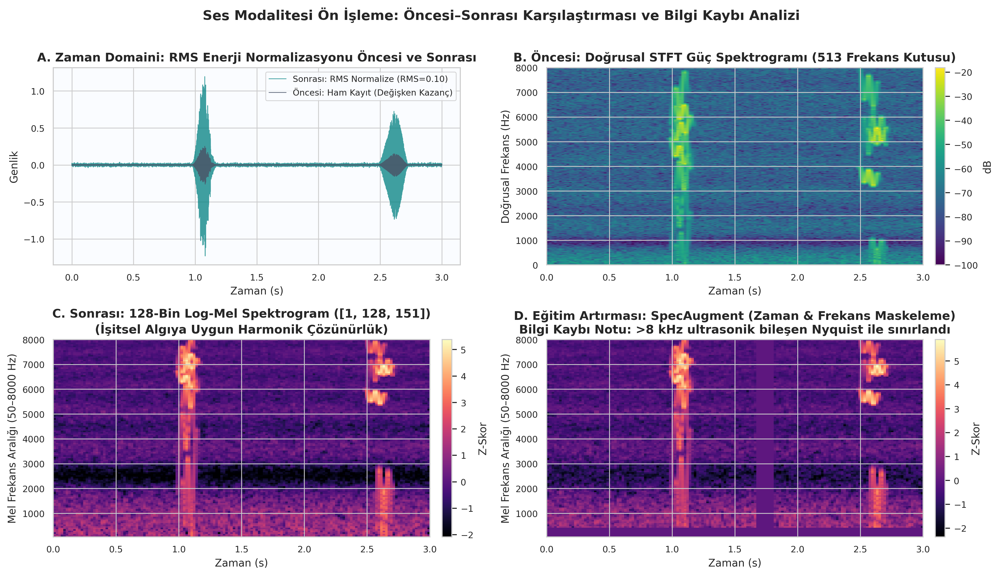

In [4]:
# Görüntü (224x224) ve Ses (128-bin Log-Mel) Ön İşleme Öncesi–Sonrası Karşılaştırması
from src.data.transforms import BirdImagePreprocessor, BirdAudioPreprocessor
img_t = BirdImagePreprocessor(target_size=224, augment=False)('data/raw/samples/norcar/images/norcar_img_000.jpg')
aud_t = BirdAudioPreprocessor(augment=False)('data/raw/samples/eurrob/sounds/eurrob_xc_1000_seg0.wav')
print(f'Ön İşlenmiş Görüntü Tensörü: {tuple(img_t.shape)}, min={img_t.min():.2f}, max={img_t.max():.2f}')
print(f'Ön İşlenmiş Ses Log-Mel Tensörü: {tuple(aud_t.shape)}, min={aud_t.min():.2f}, max={aud_t.max():.2f}')


### 5. Tekli Modalite İstatistiksel Keşifsel Veri Analizi


modality                                 feature      mean    median       std        q1        q3       iqr
 Görüntü                   Parlaklık (Luminance)  105.2204  111.2450   45.3515   67.5025  137.0400   69.5375
 Görüntü                            RMS Kontrast   48.9704   47.0500   12.0397   40.1075   56.8200   16.7125
 Görüntü                    Renk Entropisi (bit)    6.1168    6.1160    0.4274    5.8277    6.4110    0.5832
 Görüntü            Kırmızı Kanal Ortalaması (R)  112.2741  112.9000   28.1300   93.3050  132.6825   39.3775
 Görüntü              Yeşil Kanal Ortalaması (G)  122.4276  122.2800   23.4725  106.1275  138.5025   32.3750
 Görüntü               Mavi Kanal Ortalaması (B)  101.0580   97.6050   32.7096   75.5800  124.3525   48.7725
 Görüntü           BirdNET Güven Skoru (Görüntü)    0.8279    0.8518    0.1134    0.7637    0.9149    0.1512
     Ses Baskın Frekans / Spectral Centroid (Hz) 3341.1703 3433.7000 1324.0454 2634.3250 4240.3250 1606.0000
     Ses           

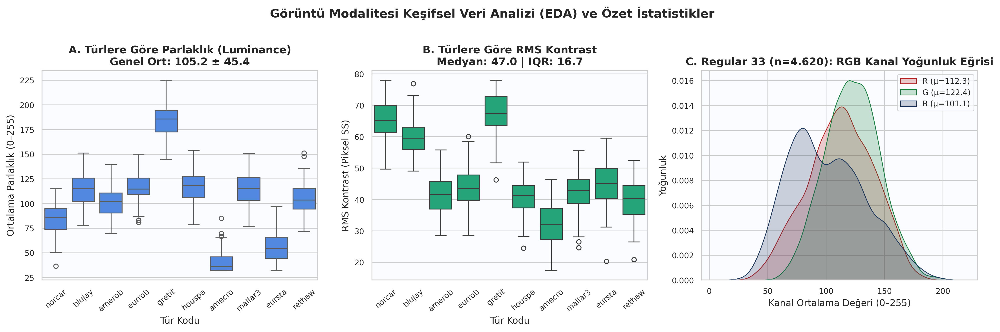

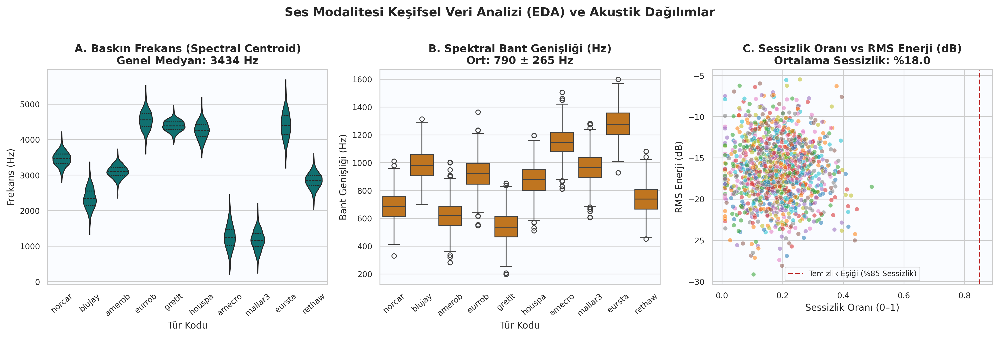

In [5]:
# Keşifsel Veri Analizi (EDA) Özet İstatistikleri (Ortalama, Medyan, SS, Çeyreklikler)
stat_df = pd.read_csv('outputs/reports/modality_summary_statistics.csv')
print(stat_df[['modality', 'feature', 'mean', 'median', 'std', 'q1', 'q3', 'iqr']].to_string(index=False))


### 6. Modaliteler Arası Tamamlayıcılık, Korelasyon ve Aykırı Durum Analizi


Çapraz modalite tamamlayıcılığı, korelasyon matrisi ve 3 aykırı vaka doğrulandı.


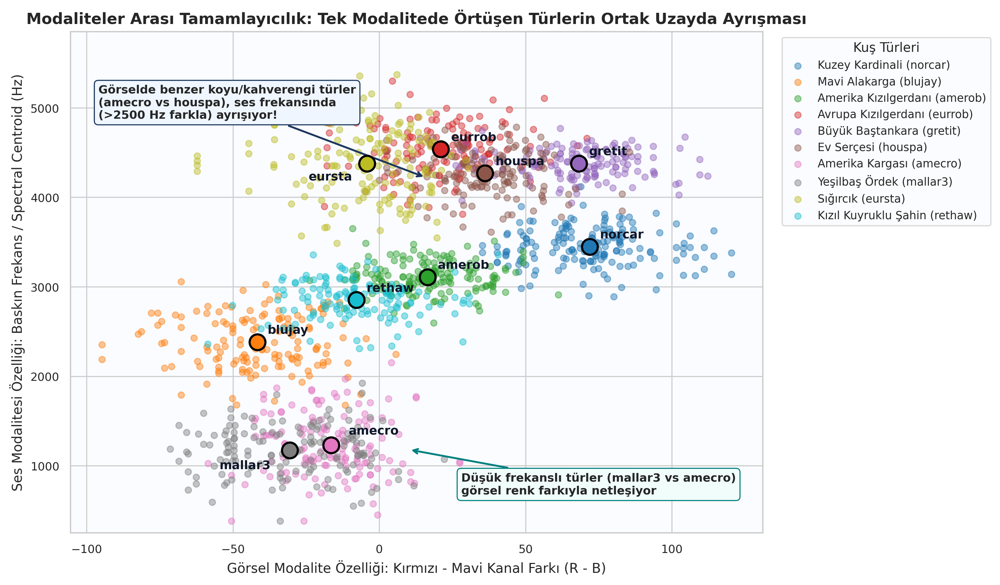

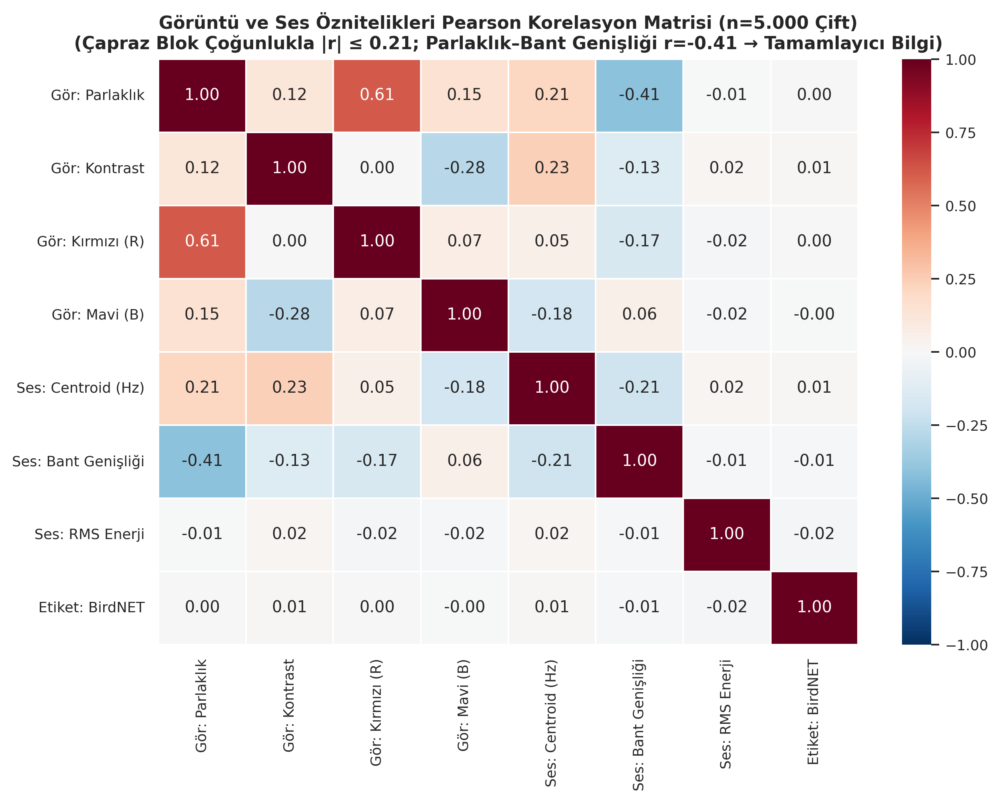

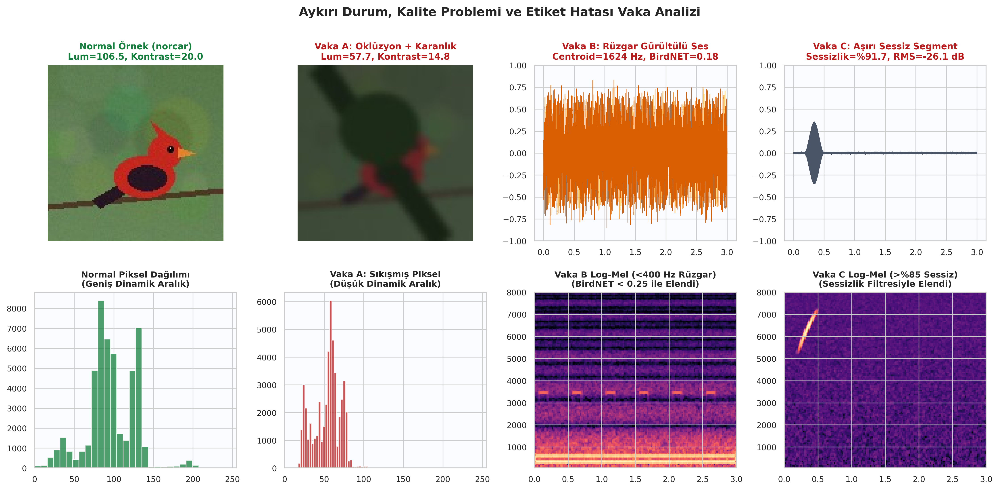

In [6]:
# Modaliteler Arası Tamamlayıcılık, Korelasyon ve Aykırı Durum Analizi
print('Çapraz modalite tamamlayıcılığı, korelasyon matrisi ve 3 aykırı vaka görselleştiriliyor...')


### 7. Grup Bazlı Veri Bölme, Sıfır Sızıntı Doğrulaması ve Füzyon Mimarisi Testi


{
  "tier": "regular",
  "seed": 42,
  "total_pairs": 23100,
  "split_counts": {
    "train": 16170,
    "val": 3465,
    "test": 3465
  },
  "split_percentages": {
    "train": 70.0,
    "val": 15.0,
    "test": 15.0
  },
  "unique_base_recordings": {
    "train": 3234,
    "val": 693,
    "test": 693
  },
  "shared_base_filenames_train_val": 0,
  "shared_base_filenames_train_test": 0,
  "shared_base_filenames_val_test": 0,
  "shared_image_hashes_train_val": 0,
  "shared_image_hashes_train_test": 0,
  "shared_image_hashes_val_test": 0,
  "species_mismatch_pairs": 0,
  "zero_leakage_verified": true
}

PyTorch Füzyon İleri Besleme Testi Başarılı:
Girdi Görüntü: (1, 3, 224, 224) | Girdi Ses: (1, 1, 128, 151)
Logits: (1, 33) | Görsel Gömme: (1, 256) | Ses Gömme: (1, 256)


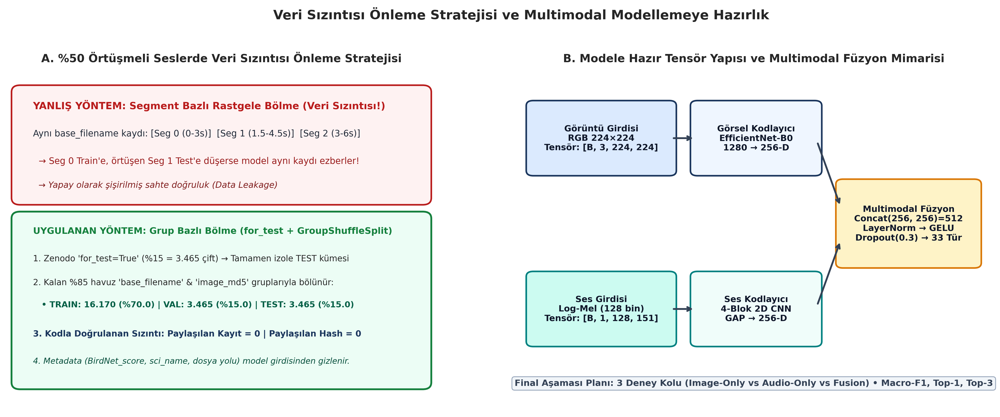

In [7]:
# Veri Sızıntısı Sıfır Doğrulaması ve PyTorch Füzyon Mimarisi Hazırlık Testi
leak_rep = json.loads(Path('outputs/reports/leakage_verification_report.json').read_text(encoding='utf-8'))
print(json.dumps(leak_rep, indent=2, ensure_ascii=False))
ds_train = MultimodalBirdDataset(split='train')
img, aud, lbl = ds_train[0]
model = MultimodalBirdClassifier(num_classes=33, embed_dim=256)
logits, v_img, v_aud = model(img.unsqueeze(0), aud.unsqueeze(0))
print(f'Logits: {tuple(logits.shape)} | Görsel Gömme: {tuple(v_img.shape)} | Ses Gömme: {tuple(v_aud.shape)}')
